# Clase 42 · Práctica «Taller espejo»
**Diplomado Data Science** · Preparación para el Taller #3 (Prof. Eloy Alvarado) · 100 % resuelto, con interpretación

> **Qué es esto.** El Taller #3 (campaña bancaria, 60 puntos, entrega 21-oct-2026) es una evaluación **grupal y calificada**. Este notebook **no contiene nada del taller**: no usa `clientes_entrenamiento.csv` ni `clientes_prueba.csv` y no entrega resultados de esa base. Resuelve **la misma estructura, pregunta por pregunta**, sobre **otra base** (la de fuga de clientes de telefonía de la Clase 33), para que veas cada técnica funcionando de punta a punta, con la interpretación que se espera. Después de cada paso hay un recuadro **«En el Taller 3 esto corresponde a…»** que dice cómo trasladar el paso a `bank` (nombres de columnas y qué cambia). **Los números, tablas y conclusiones del taller los obtiene tu grupo.**

**Material de apoyo:** `Guias/C42_Guia_Taller3.pdf` (qué se pide, dónde estudiarlo, trampas, checklist) y los notebooks de las clases 30–41 en esta misma carpeta.

### Correspondencia con el enunciado
| Taller #3 (banco) | Esta práctica (churn) | Pts |
|---|---|---|
| 1(a) tarea, unidad, respuesta, variable que no se puede usar (`duracion`) | Parte 1(a); análogo: `clv` | 3 |
| 1(b) tipos, faltantes, `unknown`, duplicados, balance; negativos y código −1 | Parte 1(b) | 4 |
| 1(c) `contactado_antes`, `log_contactos_previos`, one-hot, escalamiento | Parte 1(c): `sin_sms`, `log_frec_sms`, one-hot, escalamiento | 5 |
| 2(a) logística todas vs. 10 mejores por F de ANOVA | Parte 2(a) | 5 |
| 2(b) seis modelos con log loss, Brier, AUC OOF | Parte 2(b) | 11 |
| 2(c) interpretación | Parte 2(c) | 8 |
| 3(a) umbral por costo FP + 5·FN | Parte 3(a) | 4 |
| 3(b) prueba: métricas, ROC, matrices en t\* y 0.50 | Parte 3(b) | 6 |
| 4(a) PCA; 4(b) K-means k = 2, 3, 4 | Parte 4 | 3 + 5 |
| 5(a) Mahalanobis² y corte χ²; 5(b) interpretación | Parte 5 | 3 + 3 |

### Qué es igual y qué cambia respecto del taller
- **Igual**: semilla 2026, clase positiva = 1, validación cruzada de 5 pliegues **con una columna `pliegue` dada**, toda transformación y selección aprendida **solo con las filas de ajuste** de cada pliegue (`Pipeline` + `ColumnTransformer`), mismas configuraciones de modelos, mismas métricas, mismo costo FP + 5·FN, mismas preguntas.
- **Cambia**: la base (3 150 clientes, no 4 521), la respuesta (`fuga`, no `contrata`), las columnas y la separación entrenamiento/prueba (aquí la **creamos** 80/20 estratificada con semilla 2026; en el taller viene hecha, igual que la columna `pliegue`).

⚠️ **Antes de empezar**: `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn` y `openpyxl` (para leer el `.xlsx`). Los datos están en la carpeta de la Clase 33; el notebook la busca solo.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy.stats import chi2
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, confusion_matrix, log_loss, roc_auc_score, roc_curve, silhouette_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEMILLA = 2026                       # igual que el taller
np.random.seed(SEMILLA)

# Busca la carpeta de la Clase 33 (donde está el Excel) subiendo desde la ubicación del notebook
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if any(p.glob("Clase*33*")))
carpeta = next(raiz.glob("Clase*33*"))

print("Versiones -> python-pandas:", pd.__version__, "| numpy:", np.__version__, "| scipy:", scipy.__version__,
      "| scikit-learn:", sklearn.__version__)
print("Datos en:", carpeta.name)

Versiones -> python-pandas: 3.0.5 | numpy: 2.5.3 | scipy: 1.18.1 | scikit-learn: 1.9.0
Datos en: Clase 33 Feature Engineering metodología de selección de variables (Profesor Eduardo Rodríguez)


> **En el Taller 3 esto corresponde a…** Con `bank` leerás `pd.read_csv("clientes_entrenamiento.csv")` y `pd.read_csv("clientes_prueba.csv")` con **rutas relativas** (los dos `.csv` junto al notebook, como pide el enunciado) y no necesitas buscar ninguna carpeta. Deja impresas las **versiones de los paquetes** como arriba: el enunciado lo exige. La semilla 2026 se usa en `random_state` de todo lo aleatorio (bosque, boosting, K-means).

---
## Parte 1 · Problema, preparación y representación (12 pts en el taller)

### 1(a) Tarea, unidad de observación, respuesta, y la variable que «no existe» al predecir
La base de churn (Clase 33) tiene 3 150 clientes de una telefónica y 12 variables; `fuga = 1` si el cliente se fue. Para que la práctica sea idéntica a la del taller necesitamos tres cosas que ahí vienen dadas y aquí **construimos**:

1. `id_cliente` (identificador del registro; no es predictor).
2. Una separación **entrenamiento / prueba** 80/20 estratificada por la respuesta, con semilla 2026.
3. Una columna **`pliegue`** (1 a 5) en el entrenamiento: pliegues estratificados fijos. Desde aquí **no se vuelven a generar**: igual que en el taller, todos los modelos usan los mismos pliegues.

In [2]:
def limpiar(df):
    # Valores imposibles -> NaN (regla de negocio de la Clase 33; no aprende nada de los datos)
    df = df.copy()
    for c in ["segundos", "frec_llamadas", "frec_sms", "antiguedad", "n_contactos"]:
        df.loc[df[c] < 0, c] = np.nan
    df.loc[(df["edad"] < 15) | (df["edad"] > 100), "edad"] = np.nan
    return df


crudo = pd.read_excel(carpeta / "Base de datos Churn.xlsx")
crudo.insert(0, "id_cliente", np.arange(1, len(crudo) + 1))      # identificador del registro
print("Filas y columnas de la base completa:", crudo.shape)

# Separación 80/20 estratificada (semilla 2026). Conservamos las filas: no se elimina nada.
ent, pru = train_test_split(crudo, test_size=0.20, stratify=crudo["fuga"], random_state=SEMILLA)
ent = ent.sort_values("id_cliente").reset_index(drop=True)
pru = pru.sort_values("id_cliente").reset_index(drop=True)

# Columna `pliegue` (1..5): 5 pliegues estratificados, fijos desde ahora
ent["pliegue"] = 0
for k, (_, idx) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(ent, ent["fuga"]), start=1):
    ent.loc[idx, "pliegue"] = k

print("Entrenamiento:", ent.shape, "| Prueba:", pru.shape)
print("Tasa de fuga -> entrenamiento: %.4f | prueba: %.4f" % (ent.fuga.mean(), pru.fuga.mean()))
print(ent.groupby("pliegue")["fuga"].agg(filas="size", fugas="sum", tasa="mean").to_string())

Filas y columnas de la base completa: (3150, 14)
Entrenamiento: (2520, 15) | Prueba: (630, 14)
Tasa de fuga -> entrenamiento: 0.1571 | prueba: 0.1571
         filas  fugas   tasa
pliegue                     
1          504     79 0.1567
2          504     79 0.1567
3          504     79 0.1567
4          504     79 0.1567
5          504     80 0.1587


> **En el Taller 3 esto corresponde a…** Todo este bloque **ya viene hecho por el profesor**: `clientes_entrenamiento.csv` (3 617 filas) y `clientes_prueba.csv` (904 filas) están separados, `id_cliente` existe y `pliegue` está en el entrenamiento. **No crees tu propia separación ni tus propios pliegues**: usa la columna dada (`entrenamiento["pliegue"]`) con sus valores tal como vienen (mira `.unique()` para saber si van de 0 a 4 o de 1 a 5). La respuesta es `contrata` y la clase positiva es `contrata = 1`.

**Interpretación.**

- **Tarea**: clasificación binaria supervisada (anticipar si un cliente se fuga). **Unidad de observación**: un cliente (una fila). **Respuesta**: `fuga` (1 = se fue; es la clase positiva). La tasa es 15.7 % tanto en entrenamiento (2 520) como en prueba (630): la estratificación las deja iguales, y los cinco pliegues quedan con 504 filas y ≈ 79 fugas cada uno.
- **La variable que no se puede usar.** En el taller, `duracion` se mide **al terminar** la llamada registrada, que es justamente el evento que se quiere anticipar: no existe cuando hay que decidir a quién llamar, y además está muy asociada a la respuesta (una llamada larga suele ser una oferta aceptada). Usarla produce una métrica de validación espectacular y un modelo inservible en producción. La base de churn **no tiene** una columna idéntica, así que para ejercitar el razonamiento adoptamos un **supuesto explícito**: `clv` (valor de vida del cliente) se calcula al cierre del periodo e incorpora la permanencia realmente observada, por lo que parte de su valor es **consecuencia** de la fuga. La tabla es coherente con la sospecha: media 541 en quienes se quedan y 124 en quienes se fueron (más de 4 veces), una brecha mucho mayor que la de `antiguedad` (32.5 vs 31.6).
- **Honestidad sobre el supuesto**: en las Clases 33 y 34 `clv` se usó como predictor legítimo porque la base no documenta cuándo se calcula. Aquí la tratamos como filtrada **para practicar la regla**: «¿esta columna existiría, con este valor, en el momento en que debo predecir?». Si la respuesta es no (o no lo sé), se excluye.
- Se excluyen de los predictores `clv`, `id_cliente` (identificador: memorizarlo no generaliza), `pliegue` (partición) y `fuga` (la respuesta). Quedan 13 predictores originales.

In [3]:
# Variable análoga a `duracion`: columna que NO existiría al momento de predecir.
print(ent.groupby("fuga")[["clv", "segundos", "frec_llamadas", "n_contactos", "antiguedad"]].mean().round(2).to_string())
LEAK = ["clv"]
NO_PRED = ["id_cliente", "pliegue", "fuga"] + LEAK
print("\nColumnas excluidas de los predictores:", NO_PRED)

          clv   segundos  frec_llamadas  n_contactos  antiguedad
fuga                                                            
0    540.6500 5,077.1000        78.8300      25.7000     32.4900
1    123.7400 1,558.4500        29.5400      12.2800     31.5900

Columnas excluidas de los predictores: ['id_cliente', 'pliegue', 'fuga', 'clv']


> **En el Taller 3 esto corresponde a…** La tarea es **clasificación binaria supervisada**, la unidad de observación es **un registro (cliente y su contacto de campaña)** y la respuesta es `contrata`. La variable prohibida es **`duracion`**: se mide cuando la llamada termina y la llamada registrada es justamente el evento que se quiere anticipar («la predicción se realiza antes de la llamada»). Se excluyen `duracion`, `id_cliente`, `pliegue` y `contrata`. Argumenta con los tres ingredientes de arriba (cuándo se mide, qué contiene, qué pasaría en producción). Ojo: otras variables de la campaña (`contactos_campana` «incluida la llamada registrada») merecen al menos una mención crítica, pero el enunciado solo pide excluir `duracion`.

### 1(b) Tipos de variables, faltantes, categorías raras, duplicados y balance de clases
Se revisa **la base de entrenamiento** (la prueba se reserva). Dos cosas distintas pueden verse mal: un valor **imposible** (error de captura) y un valor **inusual pero posible**. En el taller, `saldo` negativo es posible (cuenta sobregirada) y `dias_previos = -1` es un **código** («no hubo contacto previo»), no un número de días. Aquí el equivalente son los valores negativos imposibles en `segundos`, `antiguedad`, etc. y la ausencia de categorías `unknown` (aquí los faltantes son `NaN` reales).

In [4]:
print("Tipos de variables:")
print(ent.drop(columns=["id_cliente", "pliegue"]).dtypes.to_string())

neg = (ent[["antiguedad", "segundos", "frec_llamadas", "frec_sms", "n_contactos", "edad"]] < 0).sum()
print("\nValores NEGATIVOS por variable (imposibles aquí):\n", neg.to_string())
print("Edades fuera de 15-100:", int(((ent.edad < 15) | (ent.edad > 100)).sum()))

ent_l = limpiar(ent)
fal = ent_l.drop(columns=["id_cliente", "pliegue"]).isna().sum()
print("\nFaltantes tras convertir imposibles en NaN:\n", fal[fal > 0].to_string())
print("Filas con algún faltante:", int(ent_l.drop(columns=["id_cliente", "pliegue"]).isna().any(axis=1).sum()))

cols_sin_id = [c for c in ent.columns if c not in ("id_cliente", "pliegue")]
print("\nFilas duplicadas (ignorando id y pliegue):", int(ent.duplicated(subset=cols_sin_id).sum()),
      "-> se informan y se CONSERVAN (el enunciado pide conservar las filas)")

print("\nBalance de clases (entrenamiento):")
print(ent.fuga.value_counts().rename("n").to_frame().assign(pct=lambda d: d.n / d.n.sum()).to_string())
base = max(ent.fuga.mean(), 1 - ent.fuga.mean())
print("\nExactitud de predecir SIEMPRE la clase mayoritaria (0):", round(base, 4))
print("Sensibilidad de esa regla:", 0.0)

Tipos de variables:
numero_fallas      int64
reclamos         float64
antiguedad       float64
monto              int64
segundos         float64
frec_llamadas    float64
frec_sms         float64
n_contactos      float64
tipo_plan          int64
estado             int64
edad               int64
clv              float64
fuga               int64

Valores NEGATIVOS por variable (imposibles aquí):
 antiguedad        9
segundos         17
frec_llamadas     8
frec_sms          0
n_contactos       0
edad              1
Edades fuera de 15-100: 85

Faltantes tras convertir imposibles en NaN:
 reclamos         10
antiguedad       12
segundos         51
frec_llamadas    26
frec_sms          4
n_contactos       2
edad             85
Filas con algún faltante: 166

Filas duplicadas (ignorando id y pliegue): 10 -> se informan y se CONSERVAN (el enunciado pide conservar las filas)

Balance de clases (entrenamiento):
         n    pct
fuga             
0     2124 0.8429
1      396 0.1571

Exactitud de p

> **En el Taller 3 esto corresponde a…** Haz el mismo inventario sobre `clientes_entrenamiento.csv`: `dtypes`, faltantes (`isna().sum()`), **cuántas filas tienen `unknown`** en cada categórica (`ocupacion`, `educacion`, `canal`, `resultado_previo`…; `unknown` es un valor, no un `NaN`, y **se mantiene como categoría**), duplicados (`duplicated()` ignorando `id_cliente` y `pliegue`), y `value_counts(normalize=True)` de `contrata`. Interpreta: (i) `saldo < 0` es plausible (sobregiro/deuda), no un error; (ii) `dias_previos = -1` es un **código de «sin contacto previo»**: tratarlo como −1 día distorsionaría cualquier promedio y cualquier escala; (iii) la exactitud de «nunca contrata» es la proporción de la clase mayoritaria y **no detecta ningún contrato** (sensibilidad 0), así que no basta; requiere sensibilidad, AUC, log loss y una referencia.

**Interpretación.**

- **Tipos**: todas las columnas son numéricas en el archivo, pero `tipo_plan` y `estado` son **códigos de categorías** (1/2), `reclamos` es binaria (0/1) y `monto` toma valores enteros 0–10; se tratan como categóricas/binaria según corresponda (ver 1(c)).
- **Valores imposibles**: hay negativos en `antiguedad` (9), `segundos` (17), `frec_llamadas` (8) y `edad` (1), y 85 edades fuera de 15–100. Una antigüedad, un tiempo de llamada o una frecuencia **no pueden ser negativos**: son errores de captura y se convierten en `NaN`. Contraste con el taller: un **`saldo` negativo sí es posible** (sobregiro, deuda) y es información, no error; y `dias_previos = -1` **no es un número de días** sino un **código** («sin contacto previo») que no debe promediarse ni escalarse como cantidad.
- **Faltantes**: tras la limpieza hay 166 filas (6.6 %) con algún faltante (sobre todo `edad`: 85 y `segundos`: 51). No se eliminan filas: se imputa con la **mediana del conjunto de ajuste de cada pliegue** (dentro del `Pipeline`). En el banco no hay `NaN`, pero sí la categoría `unknown`, que **se mantiene como categoría**.
- **Duplicados**: 10 filas repetidas en todas las columnas (sin `id_cliente`). Con variables mayormente discretas pueden ser clientes distintos con el mismo patrón; no hay un identificador natural para decidir, así que se informan y se **conservan**.
- **Balance**: 84.3 % no se fuga / 15.7 % se fuga. Predecir siempre «no se fuga» acierta el **84.3 %**, pero detecta **0 de 396** fugas (sensibilidad 0): una exactitud alta que no sirve para el negocio. Por eso se usan log loss, Brier, AUC, sensibilidad/especificidad y el costo, y se incluye siempre el modelo de referencia (que además fija un piso de log loss: 0.435).

### 1(c) Variables nuevas, one-hot y escalamiento «necesario para cada método»
El taller pide `contactado_antes` (indicador de que `dias_previos ≠ -1`) y `log_contactos_previos = log(1 + contactos_previos)`, reemplazar el −1 por 0 conservando el indicador, mantener `unknown` y codificar con one-hot. Los análogos en churn:

| Taller (banco) | Práctica (churn) | Idea |
|---|---|---|
| `contactado_antes = 1[dias_previos ≠ -1]` | `sin_sms = 1[frec_sms = 0]` | indicador de un **estado especial** (ausencia) que no se debe mezclar con la cantidad |
| `log_contactos_previos = log(1 + contactos_previos)` | `log_frec_sms = log(1 + frec_sms)` | conteo muy asimétrico: el log reduce la cola; `1 +` permite el cero |
| `-1 → 0` en `dias_previos` | los negativos imposibles → `NaN` → mediana (dentro del pliegue) | el código no puede entrar como número |
| `unknown` como categoría + one-hot | `tipo_plan`, `estado`, `nivel_monto` como categorías + one-hot | categorías sin orden |

Ambas variables nuevas son transformaciones **fila a fila sin parámetros aprendidos** (no usan la respuesta ni otras filas), así que se pueden calcular antes de separar sin causar fuga. En cambio **imputar medianas, escalar, one-hot (qué categorías existen) y seleccionar columnas** sí aprenden de los datos: eso va **dentro de cada pliegue**.

In [5]:
def preparar(df):
    d = limpiar(df)
    d["sin_sms"] = (d["frec_sms"] == 0).astype(int)                 # indicador (análogo a contactado_antes)
    d["log_frec_sms"] = np.log1p(d["frec_sms"])                      # log(1 + conteo) (análogo a log_contactos_previos)
    d["nivel_monto"] = pd.cut(d["monto"], [-1, 0, 1, 2, 99], labels=["m0", "m1", "m2", "m3mas"]).astype(str)
    d["tipo_plan"] = "plan" + d["tipo_plan"].astype(str)
    d["estado"] = "est" + d["estado"].astype(str)
    return d


tr = preparar(ent)
te = preparar(pru)
ytr = tr["fuga"].to_numpy()
yte = te["fuga"].to_numpy()

NUM = ["numero_fallas", "antiguedad", "segundos", "frec_llamadas", "frec_sms", "n_contactos", "edad", "log_frec_sms"]
BIN = ["reclamos", "sin_sms"]
CAT = ["tipo_plan", "estado", "nivel_monto"]
PRED = NUM + BIN + CAT
assert not set(PRED) & set(NO_PRED)
print("Predictores:", len(PRED), "->", PRED)
print("\nsin_sms: %.3f de los clientes | media de log_frec_sms: %.3f" % (tr.sin_sms.mean(), tr.log_frec_sms.mean()))
print(tr.groupby("sin_sms")["fuga"].agg(n="size", tasa_fuga="mean").to_string())

Predictores: 13 -> ['numero_fallas', 'antiguedad', 'segundos', 'frec_llamadas', 'frec_sms', 'n_contactos', 'edad', 'log_frec_sms', 'reclamos', 'sin_sms', 'tipo_plan', 'estado', 'nivel_monto']

sin_sms: 0.194 de los clientes | media de log_frec_sms: 2.952
            n  tasa_fuga
sin_sms                 
0        2031     0.1413
1         489     0.2229


**Escalamiento «necesario para cada método».** El escalamiento solo importa cuando el método usa **distancias o magnitudes**:

| Método | ¿Escalar numéricas? | Por qué |
|---|---|---|
| Regresión logística sin penalización | recomendable (estandarizar) | el ajuste es invariante a la escala, pero la optimización numérica converge mejor y los coeficientes quedan comparables |
| Logística + selección por F de ANOVA | indiferente para F; se estandariza igual por la logística | F de ANOVA compara medias entre clases dividido por varianza: no cambia con la escala |
| Árbol, Random Forest, Boosting | **no** | solo comparan «x ≤ umbral»: invariantes a transformaciones monótonas |
| SVM radial | **sí, obligatorio** | usa distancias euclidianas en el kernel: una variable en miles domina a una en unidades |
| Naive Bayes gaussiano | no | modela cada variable por separado (su propia media y varianza) |
| PCA y K-means (partes 4–5) | **sí** | varianza y distancias dependen de las unidades |

Todo el preprocesamiento se arma como un `ColumnTransformer` **dentro del `Pipeline`**: se ajusta con las filas de ajuste de cada pliegue y se aplica sin reajustar a las filas del pliegue de validación (o a la prueba).

In [6]:
def prep(escalar):
    num = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    ct = ColumnTransformer([
        ("num", Pipeline(num), NUM),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), CAT)],
        verbose_feature_names_out=False)
    return ct.set_output(transform="pandas")


# Vista de las columnas preparadas (ajustando con TODO el entrenamiento solo para listarlas)
ct = prep(True).fit(tr[PRED])
Xprep = ct.transform(tr[PRED])
P_COLS = list(Xprep.columns)
p = len(P_COLS)
print("Columnas preparadas p =", p)
print(P_COLS)
print("Con p =", p, "el gamma del SVM del enunciado es 1/p =", round(1 / p, 5))

Columnas preparadas p = 16
['numero_fallas', 'antiguedad', 'segundos', 'frec_llamadas', 'frec_sms', 'n_contactos', 'edad', 'log_frec_sms', 'reclamos', 'sin_sms', 'tipo_plan_plan2', 'estado_est2', 'nivel_monto_m0', 'nivel_monto_m1', 'nivel_monto_m2', 'nivel_monto_m3mas']
Con p = 16 el gamma del SVM del enunciado es 1/p = 0.0625


> **En el Taller 3 esto corresponde a…** `contactado_antes = (dias_previos != -1).astype(int)`; `dias_previos = dias_previos.replace(-1, 0)` **después** de crear el indicador (si no, pierdes la información); `log_contactos_previos = np.log1p(contactos_previos)`. Las binarias `mora`, `hipoteca`, `prestamo` son `yes/no`: pásalas a 1/0 (o déjalas en el one-hot). Las categóricas son `ocupacion`, `estado_civil`, `educacion`, `canal`, `mes`, `resultado_previo` (y decide qué haces con `dia` y `mes`: documenta tu decisión). **Mantén `unknown` como una categoría más** (no lo imputes). `OneHotEncoder(handle_unknown="ignore")` dentro del `ColumnTransformer`; escala solo las numéricas continuas (`edad`, `saldo`, `contactos_campana`, `dias_previos`, `log_contactos_previos`, …) y **solo para los métodos que lo necesitan** (tabla de arriba). Y recuerda: `p` en `gamma = 1/p` es el número de columnas **ya preparadas** (después del one-hot), no el de columnas originales.

---
## Parte 2 · Selección de variables y modelos supervisados (24 pts)

### Un motor de validación cruzada con la columna `pliegue` dada
Para cada pliegue `k`: las filas con `pliegue ≠ k` son las **filas de ajuste** (todo se aprende ahí: imputación, escala, one-hot, selección de columnas, modelo) y las filas con `pliegue = k` son las de **validación**, de donde salen las predicciones fuera de pliegue (OOF): probabilidades para los modelos probabilísticos y **puntajes de decisión** para la SVM. Se mide además el log loss **de entrenamiento** de cada ajuste (necesario para los árboles).

El **modelo de referencia** predice, en cada pliegue, la proporción positiva de las filas de ajuste (`DummyClassifier(strategy="prior")`).

In [7]:
PLIEGUES = sorted(tr["pliegue"].unique())


def oof(modelo, svm=False):
    # Predicciones fuera de pliegue con la columna `pliegue` dada. Devuelve (pred, ajustes, log loss de entrenamiento por ajuste).
    pred = np.zeros(len(tr))
    ajustes, ll_ent = [], []
    for k in PLIEGUES:
        aj = (tr["pliegue"] != k).to_numpy()
        va = ~aj
        m = clone(modelo).fit(tr.loc[aj, PRED], ytr[aj])
        if svm:
            pred[va] = m.decision_function(tr.loc[va, PRED])
        else:
            pred[va] = m.predict_proba(tr.loc[va, PRED])[:, 1]
            ll_ent.append(log_loss(ytr[aj], m.predict_proba(tr.loc[aj, PRED])[:, 1]))
        ajustes.append(m)
    return pred, ajustes, ll_ent


def metricas(pred, svm=False):
    por_pliegue = [roc_auc_score(ytr[tr["pliegue"].to_numpy() == k], pred[tr["pliegue"].to_numpy() == k]) for k in PLIEGUES]
    out = {"AUC": roc_auc_score(ytr, pred), "AUC medio por pliegue": float(np.mean(por_pliegue))}
    if not svm:
        out = {"log loss": log_loss(ytr, pred), "Brier": brier_score_loss(ytr, pred), **out}
    return out


# --- Las siete configuraciones de la tabla del enunciado (más la referencia)
LR = dict(penalty=None, max_iter=5000)               # sin penalización
MODELOS = {
    "Referencia (tasa positiva)": Pipeline([("prep", prep(False)), ("m", DummyClassifier(strategy="prior"))]),
    "Logística (todas las columnas)": Pipeline([("prep", prep(True)), ("m", LogisticRegression(**LR))]),
    "Logística (10 mejores por F)": Pipeline([("prep", prep(True)), ("sel", SelectKBest(f_classif, k=10)), ("m", LogisticRegression(**LR))]),
    "Árbol prof. 3": Pipeline([("prep", prep(False)), ("m", DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEMILLA))]),
    "Árbol prof. 6": Pipeline([("prep", prep(False)), ("m", DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=SEMILLA))]),
    "Random Forest": Pipeline([("prep", prep(False)), ("m", RandomForestClassifier(n_estimators=200, max_features="sqrt", min_samples_leaf=10,
                                                                                    random_state=SEMILLA, n_jobs=-1))]),
    "Boosting (GradientBoosting)": Pipeline([("prep", prep(False)), ("m", GradientBoostingClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05, n_iter_no_change=20, validation_fraction=0.1, random_state=SEMILLA))]),
    "SVM radial": Pipeline([("prep", prep(True)), ("m", SVC(kernel="rbf", C=1.0, gamma="auto"))]),     # gamma='auto' = 1/p
    "Naive Bayes gaussiano": Pipeline([("prep", prep(False)), ("m", GaussianNB())]),
}
SVM = {"SVM radial"}

RES, AJ, LLENT, OOF = {}, {}, {}, {}
for nombre, mod in MODELOS.items():
    pred, ajs, ll = oof(mod, svm=nombre in SVM)
    OOF[nombre], AJ[nombre], LLENT[nombre] = pred, ajs, ll
    RES[nombre] = metricas(pred, svm=nombre in SVM)
print("Modelos ajustados con", len(PLIEGUES), "pliegues cada uno:", len(RES), "modelos")

Modelos ajustados con 5 pliegues cada uno: 9 modelos


> **En el Taller 3 esto corresponde a…** Usa **la columna `pliegue` que viene en `clientes_entrenamiento.csv`**: `for k in sorted(entrenamiento["pliegue"].unique())`. **No** uses `cross_val_score(cv=5)`, `StratifiedKFold` ni `GridSearchCV` con tus propios pliegues: el enunciado pide «los cinco pliegues entregados» (es un punto que se pierde). Para cada pliegue: separar `ajuste = pliegue != k` y `valid = pliegue == k`, ajustar el `Pipeline` solo con `ajuste` y guardar la predicción de `valid` en un vector OOF alineado con las filas. Respuesta `contrata`; clase positiva 1. El **modelo de referencia** en cada pliegue es `ajuste["contrata"].mean()` aplicado a todas las filas de `valid` (y, en la evaluación final, la tasa de **todo** el entrenamiento). Boosting: elige **una** variante vista en clase (p. ej. `GradientBoostingClassifier`, `AdaBoost`, `HistGradientBoosting`, `XGBoost`), con ≤ 200 árboles, `max_depth = 3`, e **informa la variante y la tasa de aprendizaje**.

### 2(a) Logística con todas las columnas vs. con las 10 de mayor F de ANOVA (5 pts)
`SelectKBest(f_classif, k=10)` está **dentro** del `Pipeline`, de modo que en cada pliegue el estadístico F se calcula solo con las filas de ajuste. La lista de columnas elegidas puede cambiar de un pliegue a otro: se informa pliegue por pliegue.

In [8]:
sel_tab = {}
for k, m in zip(PLIEGUES, AJ["Logística (10 mejores por F)"]):
    sel_tab[f"pliegue {k}"] = np.array(P_COLS)[m.named_steps["sel"].get_support()]
sel_df = pd.DataFrame(sel_tab)
sel_df.index = [f"#{i}" for i in range(1, 11)]
print("Columnas seleccionadas (top 10 por F) en cada pliegue:")
print(sel_df.to_string())

frec = pd.Series(np.concatenate(list(sel_tab.values()))).value_counts()
print("\nEn cuántos de los 5 pliegues fue elegida cada columna:")
print(frec.to_string())
print("Columnas que NUNCA se eligen:", sorted(set(P_COLS) - set(frec.index)))

Columnas seleccionadas (top 10 por F) en cada pliegue:
             pliegue 1          pliegue 2          pliegue 3          pliegue 4          pliegue 5
#1            segundos           segundos           segundos           segundos           segundos
#2       frec_llamadas      frec_llamadas      frec_llamadas      frec_llamadas      frec_llamadas
#3            frec_sms           frec_sms           frec_sms           frec_sms           frec_sms
#4         n_contactos        n_contactos        n_contactos        n_contactos        n_contactos
#5        log_frec_sms       log_frec_sms       log_frec_sms       log_frec_sms       log_frec_sms
#6            reclamos           reclamos           reclamos           reclamos           reclamos
#7         estado_est2        estado_est2        estado_est2        estado_est2        estado_est2
#8      nivel_monto_m0     nivel_monto_m0     nivel_monto_m0     nivel_monto_m0     nivel_monto_m0
#9      nivel_monto_m1     nivel_monto_m1     nivel_mo

In [9]:
tab_a = pd.DataFrame({n: RES[n] for n in ["Logística (todas las columnas)", "Logística (10 mejores por F)"]}).T
print(tab_a.to_string())

# Limitación del filtro univariado: no mira redundancia entre columnas (F se calcula una columna a la vez)
m1 = AJ["Logística (10 mejores por F)"][0]
Xaj = prep(True).fit_transform(tr.loc[tr.pliegue != PLIEGUES[0], PRED])
elegidas = list(sel_df["pliegue 1"])
cor = Xaj[elegidas].corr().abs().where(lambda d: np.triu(np.ones(d.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("\nPares más correlacionados ENTRE las 10 columnas elegidas (pliegue 1):")
print(cor.head(5).to_string())

                                log loss  Brier    AUC  AUC medio por pliegue
Logística (todas las columnas)    0.2461 0.0771 0.9168                 0.9174
Logística (10 mejores por F)      0.2555 0.0792 0.9079                 0.9081

Pares más correlacionados ENTRE las 10 columnas elegidas (pliegue 1):
segundos        frec_llamadas    0.9337
frec_sms        log_frec_sms     0.7744
frec_llamadas   n_contactos      0.7515
segundos        n_contactos      0.6911
nivel_monto_m0  nivel_monto_m1   0.5634


> **En el Taller 3 esto corresponde a…** Mismo experimento con tus columnas preparadas (después del one-hot): `SelectKBest(f_classif, k=10)` entre el preprocesamiento y la logística, **dentro del Pipeline**. Para informar las columnas de cada pliegue: `pipe.named_steps["sel"].get_support()` sobre los nombres de `pipe.named_steps["prep"].get_feature_names_out()`. Verifica que **p > 10** (si no, no hay nada que seleccionar). Tabla pedida: columnas por pliegue + log loss/Brier/AUC OOF de las dos logísticas. «Sin penalización»: `LogisticRegression(penalty=None)` en scikit-learn, `glm(family = binomial)` en R. Respuestas conceptuales: (i) F de ANOVA es un **filtro supervisado** que ordena columnas **una a una** según cuánto separan las medias de `contrata`; PCA es **no supervisado** y **crea** combinaciones nuevas que maximizan varianza sin mirar la respuesta; (ii) el filtro univariado ignora la **redundancia** y las **interacciones**: puede elegir dos columnas casi idénticas y descartar una que solo es útil junto a otra.

**Interpretación.**

| Modelo | log loss OOF | Brier OOF | AUC OOF |
|---|---|---|---|
| Logística, 16 columnas | 0.2461 | 0.0771 | 0.9168 |
| Logística, 10 mejores por F | 0.2555 | 0.0792 | 0.9079 |

- **Columnas seleccionadas**: en los cinco pliegues se eligen **las mismas 10** (`segundos`, `frec_llamadas`, `frec_sms`, `n_contactos`, `log_frec_sms`, `reclamos`, `estado_est2` y tres dummies de `nivel_monto`). Nunca se eligen `antiguedad`, `edad`, `nivel_monto_m2`, `numero_fallas`, `sin_sms` ni `tipo_plan_plan2`. La estabilidad no es una regla general: aquí cada ajuste usa ≈ 2 016 filas y las diferencias de F entre columnas fuertes y débiles son grandes; con menos filas o columnas de F parecido la lista cambiaría de un pliegue a otro, y eso también se informa.
- **Comparación**: la versión con 10 columnas es **algo peor en las tres métricas** (log loss +0.009, AUC −0.009). Con 16 columnas y ≈ 2 000 filas de ajuste la logística casi no sobreajusta, así que quitar columnas no ayuda a generalizar y se pierde algo de señal (una columna con F bajo **por sí sola** puede aportar al combinarse con otras).
- **Diferencia con PCA**: F de ANOVA es un **filtro supervisado**: puntúa cada columna original según cuánto separan sus medias las dos clases (usa la respuesta) y **conserva columnas interpretables**. PCA es **no supervisado**: **crea** combinaciones lineales nuevas que maximizan la varianza, sin mirar la respuesta, y las columnas originales dejan de verse.
- **Limitación del filtro univariado**: puntúa **una columna a la vez**, ignorando redundancia e interacciones. Entre las 10 elegidas, `segundos` y `frec_llamadas` tienen |r| = 0.93 y `frec_sms` con `log_frec_sms` 0.77: el filtro se queda con varias versiones de la misma información y puede dejar fuera columnas que solo ayudan en conjunto. Además, las dummies de una misma variable (`nivel_monto`) se evalúan por separado.

### 2(b) Comparación de las configuraciones (11 pts)
Métricas OOF: **log loss**, **Brier** y **AUC** para los modelos probabilísticos; solo **AUC** para la SVM (el puntaje de decisión no es una probabilidad). Para los **dos árboles** se agrega el log loss **medio de entrenamiento** de los cinco ajustes. Las métricas globales se calculan sobre el vector OOF completo (las 2 520 predicciones); se añade el AUC medio por pliegue como chequeo.

In [10]:
tabla = pd.DataFrame(RES).T
tabla["log loss entren. (medio 5 ajustes)"] = [np.mean(LLENT[n]) if n.startswith("Árbol") else np.nan for n in tabla.index]
cols = ["log loss", "Brier", "AUC", "AUC medio por pliegue", "log loss entren. (medio 5 ajustes)"]
print(tabla[cols].to_string(na_rep="—"))

prob = tabla.drop(index=["Referencia (tasa positiva)", "SVM radial"])
ELEGIDO = prob["log loss"].idxmin()
print("\nModelo probabilístico con MENOR log loss OOF (sin contar la referencia):", ELEGIDO)
print("Boosting: variante = GradientBoostingClassifier, tasa de aprendizaje = 0.05, árboles por pliegue =",
      [m.named_steps["m"].n_estimators_ for m in AJ["Boosting (GradientBoosting)"]])
print("Árboles por pliegue: hojas prof.3 =", [int(m.named_steps["m"].get_n_leaves()) for m in AJ["Árbol prof. 3"]],
      "| prof.6 =", [int(m.named_steps["m"].get_n_leaves()) for m in AJ["Árbol prof. 6"]])

                                log loss  Brier    AUC  AUC medio por pliegue  log loss entren. (medio 5 ajustes)
Referencia (tasa positiva)        0.4349 0.1324 0.4988                 0.5000                                   —
Logística (todas las columnas)    0.2461 0.0771 0.9168                 0.9174                                   —
Logística (10 mejores por F)      0.2555 0.0792 0.9079                 0.9081                                   —
Árbol prof. 3                     0.2951 0.0852 0.8556                 0.8405                              0.2635
Árbol prof. 6                     0.4008 0.0802 0.9034                 0.9030                              0.2013
Random Forest                     0.2016 0.0614 0.9591                 0.9592                                   —
Boosting (GradientBoosting)       0.1789 0.0545 0.9618                 0.9622                                   —
SVM radial                             —      — 0.9356                 0.9357           

> **En el Taller 3 esto corresponde a…** La tabla final del taller tiene **las mismas filas** (referencia, logística todas, logística top-10, árbol 3, árbol 6, Random Forest, Boosting, SVM, Naive Bayes) y las mismas columnas. Trampas: **SVM** → `SVC(kernel="rbf", C=1, gamma=1/p)` (`gamma="auto"` hace exactamente `1/p` en scikit-learn; en R `e1071::svm(gamma = 1/p)`) con **`decision_function`** y **solo AUC** (no calcules log loss ni Brier con puntajes sin calibrar); **árboles** → `max_depth` 3 y 6 con `min_samples_leaf = 20`, más el log loss medio de entrenamiento **de los cinco ajustes** (calcula el log loss sobre `ajuste` en cada pliegue y promedia); **Random Forest** → `n_estimators = 200`, `max_features = "sqrt"`, `min_samples_leaf = 10`; **Naive Bayes** → variante gaussiana (`GaussianNB`) sobre las columnas numéricas y binarias preparadas. La selección del modelo se hace **por menor log loss OOF entre los probabilísticos** (no por AUC). Escribe la regla de selección en el notebook: el enunciado acepta ganadores distintos «cuando la regla esté justificada».

**Interpretación.**

- **Selección**: se define de antemano la regla «menor log loss OOF entre los modelos probabilísticos (sin contar la referencia)». Gana **Boosting** (0.1789; Brier 0.0545; AUC 0.9618), seguido de Random Forest (0.2016). La SVM (solo AUC: 0.9356) queda tercera en orden, pero **no compite en probabilidades** porque su puntaje no lo es.
- **Boosting informado**: `GradientBoostingClassifier`, hasta 200 árboles de profundidad 3, tasa de aprendizaje 0.05, con detención temprana (10 % de las filas **de ajuste** como validación interna, de modo que tampoco hay fuga); usó 173, 200, 133, 200 y 200 árboles en los cinco pliegues.
- **Referencia**: log loss 0.4349, Brier 0.1324 y AUC ≈ 0.5 (0.4988 en el OOF conjunto porque la constante cambia levemente entre pliegues; 0.5000 como media por pliegue). Todo modelo útil debe ganarle por amplio margen.
- **Naive Bayes** tiene un AUC decente (0.890) pero un log loss de **1.46, más de tres veces el de la referencia**: ordena bien y asigna probabilidades pésimas (ver 2(c)).
- **Árboles**: profundidad 3 → log loss de entrenamiento 0.2635 y OOF 0.2951; profundidad 6 → entrenamiento 0.2013 pero OOF **0.4008**. El AUC sí mejora con la profundidad (0.856 → 0.903): ordenar y dar buenas probabilidades son cosas distintas.
- Un ganador distinto en el banco es perfectamente aceptable si la regla de selección está escrita y justificada.

### 2(c) Interpretación (8 pts)
Cinco evidencias numéricas respaldan cada punto antes de escribir la interpretación: (1) brecha entrenamiento–OOF de los árboles; (2) tamaño de los bosques vs. árbol único; (3) calibración y extremos de Naive Bayes; (4) efecto de C, gamma y escalamiento en la SVM; (5) ranking vs. probabilidad.

In [11]:
# (1) Árboles: profundidad y sobreajuste (entrenamiento vs. OOF)
arb = pd.DataFrame({n: {"log loss entrenamiento": np.mean(LLENT[n]), "log loss OOF": RES[n]["log loss"],
                        "brecha": RES[n]["log loss"] - np.mean(LLENT[n]), "AUC OOF": RES[n]["AUC"]}
                    for n in ["Árbol prof. 3", "Árbol prof. 6", "Random Forest", "Boosting (GradientBoosting)"]}).T
arb["log loss entrenamiento"] = [np.mean(LLENT[n]) for n in arb.index]
arb["brecha"] = arb["log loss OOF"] - arb["log loss entrenamiento"]
print(arb.to_string())

# (3) Naive Bayes: cuán extremas son sus probabilidades, y calibración por tramos de probabilidad
def extremos(v):
    return {"p<0.01": np.mean(v < 0.01), "p>0.99": np.mean(v > 0.99), "min": v.min(), "max": v.max()}
print("\nExtremos de las probabilidades OOF:")
print(pd.DataFrame({n: extremos(OOF[n]) for n in ["Naive Bayes gaussiano", "Logística (todas las columnas)", "Random Forest", ELEGIDO]}).T.to_string())

def calibracion(v, y, tramos=(0, .05, .10, .20, .40, .60, 1.0)):
    g = pd.cut(v, list(tramos), include_lowest=True)
    d = pd.DataFrame({"p": v, "y": y, "g": g}).groupby("g", observed=True).agg(n=("y", "size"), p_media=("p", "mean"), tasa_obs=("y", "mean"))
    return d
print("\nCalibración OOF de Naive Bayes (p media vs. tasa observada):")
print(calibracion(OOF["Naive Bayes gaussiano"], ytr).to_string())

                             log loss entrenamiento  log loss OOF  brecha  AUC OOF
Árbol prof. 3                                0.2635        0.2951  0.0316   0.8556
Árbol prof. 6                                0.2013        0.4008  0.1995   0.9034
Random Forest                                0.1638        0.2016  0.0377   0.9591
Boosting (GradientBoosting)                  0.1249        0.1789  0.0540   0.9618

Extremos de las probabilidades OOF:
                                p<0.01  p>0.99    min    max
Naive Bayes gaussiano           0.5075  0.2631 0.0000 1.0000
Logística (todas las columnas)  0.3460  0.0004 0.0000 0.9910
Random Forest                   0.2956  0.0000 0.0000 0.9403
Boosting (GradientBoosting)     0.2698  0.0024 0.0014 0.9959

Calibración OOF de Naive Bayes (p media vs. tasa observada):
                   n  p_media  tasa_obs
g                                      
(-0.001, 0.05]  1347   0.0015    0.0178
(0.05, 0.1]       31   0.0725    0.1290
(0.1, 0.2]        49 

In [12]:
# (4) SVM: efecto de C, gamma y escalamiento (AUC OOF con las mismas pliegues)
p_ = p
variantes = {
    "Enunciado: C=1, gamma=1/p, ESCALADA": (prep(True), dict(C=1, gamma=1 / p_)),
    "C=0.1, gamma=1/p":                    (prep(True), dict(C=0.1, gamma=1 / p_)),
    "C=10, gamma=1/p":                     (prep(True), dict(C=10, gamma=1 / p_)),
    "C=1, gamma=0.1/p (más suave)":        (prep(True), dict(C=1, gamma=0.1 / p_)),
    "C=1, gamma=10/p (más local)":         (prep(True), dict(C=1, gamma=10 / p_)),
    "C=1, gamma=1/p, SIN escalar":         (prep(False), dict(C=1, gamma=1 / p_)),
}
filas = {}
for nom, (pp, kw) in variantes.items():
    pr, _, _ = oof(Pipeline([("prep", pp), ("m", SVC(kernel="rbf", **kw))]), svm=True)
    filas[nom] = {"AUC OOF": roc_auc_score(ytr, pr)}
print(pd.DataFrame(filas).T.to_string())

# (5) ¿Mejor orden implica mejores probabilidades?  El AUC solo depende del ORDEN; el log loss, de los valores.
pe = OOF[ELEGIDO]
print("\nTransformación monótona de las probabilidades del modelo elegido (%s):" % ELEGIDO)
for etiqueta, v in [("original", pe), ("p^3 (mismo orden, probabilidades deformadas)", pe ** 3), ("sqrt(p)", np.sqrt(pe))]:
    v = np.clip(v, 1e-9, 1 - 1e-9)
    print(f"  {etiqueta:48s} AUC = {roc_auc_score(ytr, v):.4f} | log loss = {log_loss(ytr, v):.4f} | Brier = {brier_score_loss(ytr, v):.4f}")
print("\nRanking por AUC vs. ranking por log loss (modelos probabilísticos):")
rk = prob[["AUC", "log loss"]].copy()
rk["rango AUC"] = rk["AUC"].rank(ascending=False).astype(int)
rk["rango log loss"] = rk["log loss"].rank().astype(int)
print(rk.sort_values("rango log loss").to_string())

                                     AUC OOF
Enunciado: C=1, gamma=1/p, ESCALADA   0.9356
C=0.1, gamma=1/p                      0.9121
C=10, gamma=1/p                       0.9535
C=1, gamma=0.1/p (más suave)          0.9092
C=1, gamma=10/p (más local)           0.9327
C=1, gamma=1/p, SIN escalar           0.6230

Transformación monótona de las probabilidades del modelo elegido (Boosting (GradientBoosting)):
  original                                         AUC = 0.9618 | log loss = 0.1789 | Brier = 0.0545
  p^3 (mismo orden, probabilidades deformadas)     AUC = 0.9618 | log loss = 0.3278 | Brier = 0.0792
  sqrt(p)                                          AUC = 0.9618 | log loss = 0.2699 | Brier = 0.0732

Ranking por AUC vs. ranking por log loss (modelos probabilísticos):
                                  AUC  log loss  rango AUC  rango log loss
Boosting (GradientBoosting)    0.9618    0.1789          1               1
Random Forest                  0.9591    0.2016          2        

> **En el Taller 3 esto corresponde a…** Estas cinco evidencias se calculan igual con los OOF de **tus** modelos y apoyan cada línea de la pregunta 2(c): *profundidad y sobreajuste* (log loss de entrenamiento muy inferior al OOF en el árbol profundo); *bagging vs. Random Forest vs. boosting* (varianza vs. sesgo, decorrelación de árboles por `max_features`, corrección secuencial de errores con tasa de aprendizaje); *independencia condicional* (Naive Bayes asume que, dado `contrata`, las columnas son independientes; con muchas columnas correlacionadas o dummies de la misma variable esa suposición se rompe y las probabilidades se vuelven extremas); *gaussiana sobre columnas binarias* (una dummy 0/1 no es normal: su «campana» es un artefacto; las probabilidades salen mal calibradas aunque el orden sea aceptable); *C, gamma y escala* (C controla cuánto se castiga el error vs. margen; gamma el alcance del kernel; sin escalar domina la variable de mayor magnitud). Cierre obligatorio: **un mejor ordenamiento (AUC) no implica mejores probabilidades (log loss/Brier)**; demuéstralo con tu propia tabla o con una transformación monótona como arriba.

**Interpretación** (con las evidencias de las celdas anteriores).

1. **Profundidad y sobreajuste de los árboles.** Al pasar de profundidad 3 (≈ 7 hojas) a 6 (≈ 23 hojas) el log loss de **entrenamiento baja** (0.2635 → 0.2013) pero el **OOF sube** (0.2951 → 0.4008): la brecha crece de 0.03 a 0.20. Hojas con pocas observaciones (mínimo 20) producen probabilidades casi 0 o 1 que fallan fuera de la muestra, y el log loss castiga mucho esos errores confiados. La brecha entrenamiento–validación es la señal de sobreajuste.
2. **Bagging, Random Forest y boosting.** Un árbol profundo tiene **varianza alta**. *Bagging* promedia árboles entrenados sobre remuestras bootstrap y baja la varianza; *Random Forest* añade un sorteo de columnas en cada división (aquí √16 = 4) para **decorrelacionar** los árboles, de modo que el promedio mejore más. *Boosting* construye árboles pequeños **en secuencia**, cada uno corrigiendo los errores del anterior, y reduce el **sesgo**; la tasa de aprendizaje (0.05) y la detención temprana controlan el sobreajuste. Resultado: RF (0.2016) y boosting (0.1789) superan por mucho al mejor árbol individual (0.2951), y boosting gana en las tres métricas.
3. **Naive Bayes.** Supone **independencia condicional**: dada la respuesta, las columnas serían independientes. Aquí es falsa (|r| = 0.93 entre `segundos` y `frec_llamadas`; `log_frec_sms` es función de `frec_sms`; las dummies de `nivel_monto` son mutuamente excluyentes), así que la misma información se multiplica varias veces y las probabilidades se vuelven **extremas**: 51 % de las predicciones OOF es < 0.01 y 26 % es > 0.99. En la calibración, donde predice ≈ 0.97 (982 clientes) la tasa observada es solo 36 %. La variante **gaussiana** además modela columnas **binarias** (`reclamos`, `sin_sms`, dummies) como normales con media y varianza propias de cada clase: una columna 0/1 no es normal y su varianza pequeña genera razones de verosimilitud desproporcionadas. Orden aceptable (AUC 0.890), probabilidades inservibles (log loss 1.46).
4. **SVM: C, gamma y escalamiento.** Con la configuración del enunciado (C = 1, gamma = 1/p = 0.0625, variables escaladas) el AUC OOF es 0.9356. **C** controla el castigo al error frente al margen: con C = 0.1 baja a 0.9121 (modelo demasiado rígido) y con C = 10 sube a 0.9535 (más flexible; no se usa porque el enunciado fija C = 1, pero muestra que el valor importa). **Gamma** fija el alcance del kernel: un gamma 10 veces menor da 0.9092 (frontera casi lineal) y 10 veces mayor 0.9327 (más local). El **escalamiento** es decisivo: sin escalar el AUC cae a **0.623**, porque `segundos` y las frecuencias (miles) dominan las distancias del kernel. Además, el puntaje de decisión no está acotado ni calibrado: solo sirve para ordenar.
5. **¿Mejor ordenamiento implica mejores probabilidades? No.** El AUC depende **solo del orden**: al elevar las probabilidades del modelo elegido al cubo, el AUC se mantiene en 0.9618, pero el log loss pasa de 0.1789 a 0.3278 (y con la raíz, a 0.2699). En la tabla real: el árbol de profundidad 6 tiene mejor AUC que el de profundidad 3 (0.903 vs 0.856) y peor log loss (0.401 vs 0.295); Naive Bayes ordena bien y calibra pésimo. Un buen ordenamiento es **necesario pero no suficiente** cuando la decisión usa las probabilidades (por ejemplo, el umbral por costo de la Parte 3).

---
## Parte 3 · Evaluación y decisión (10 pts)

### 3(a) Umbral que minimiza el costo hipotético (4 pts)
Con las probabilidades OOF del modelo elegido se evalúan los umbrales 0.05, 0.10, …, 0.95. Se predice «fuga» si `p ≥ t`. El costo es

$$C(t) = FP(t) + 5\,FN(t)$$

donde **FP** es una alerta de fuga que no ocurre (contactar a quien no se iba) y **FN** una fuga no detectada (perder a quien sí se iba). El umbral elegido es el de menor costo (si hay empate, el menor `t`).

Modelo elegido: Boosting (GradientBoosting)
          VN   FP   FN   VP  costo C(t)  sensibilidad  especificidad
t                                                                   
0.0500  1553  571    7  389         606        0.9823         0.7312
0.1000  1793  331   17  379         416        0.9571         0.8442
0.1500  1888  236   31  365         391        0.9217         0.8889
0.2000  1935  189   44  352         409        0.8889         0.9110
0.2500  1975  149   61  335         454        0.8460         0.9298
0.3000  1997  127   74  322         497        0.8131         0.9402
0.3500  2018  106   85  311         531        0.7854         0.9501
0.4000  2033   91  104  292         611        0.7374         0.9572
0.4500  2043   81  127  269         716        0.6793         0.9619
0.5000  2054   70  137  259         755        0.6540         0.9670
0.5500  2072   52  159  237         847        0.5985         0.9755
0.6000  2081   43  183  213         958        0.5379      

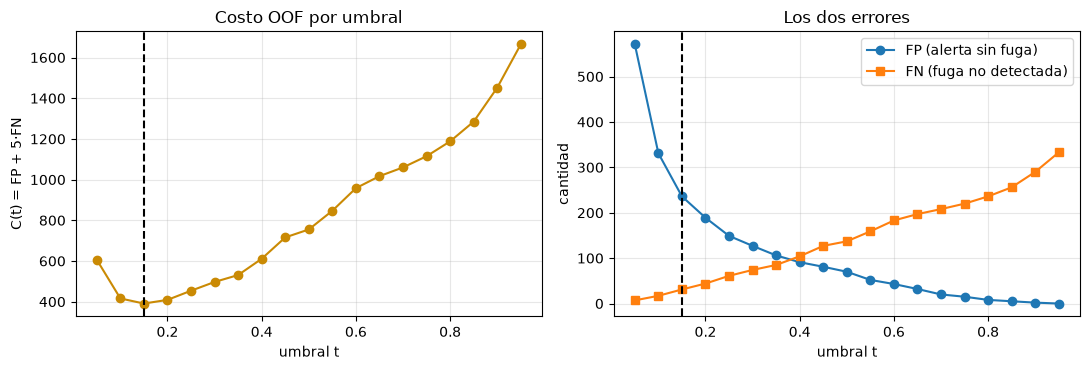

In [13]:
UMBRALES = np.round(np.arange(0.05, 0.951, 0.05), 2)


def matriz(y, pred_pos):
    tn, fp, fn, tp = confusion_matrix(y, pred_pos, labels=[0, 1]).ravel()
    return int(tn), int(fp), int(fn), int(tp)


filas = []
for t in UMBRALES:
    tn, fp, fn, tp = matriz(ytr, pe >= t)
    filas.append({"t": t, "VN": tn, "FP": fp, "FN": fn, "VP": tp, "costo C(t)": fp + 5 * fn,
                  "sensibilidad": tp / (tp + fn), "especificidad": tn / (tn + fp)})
curva = pd.DataFrame(filas).set_index("t")
T_STAR = float(curva["costo C(t)"].idxmin())
print("Modelo elegido:", ELEGIDO)
print(curva.to_string())
print("\nUmbral elegido t* =", T_STAR, "| costo mínimo =", int(curva.loc[T_STAR, "costo C(t)"]),
      "| costo en t = 0.50:", int(curva.loc[0.50, "costo C(t)"]))
print("Referencias: no alertar a nadie cuesta 5·(fugas) =", 5 * int(ytr.sum()), "| alertar a todos cuesta (no fugas) =", int((1 - ytr).sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(curva.index, curva["costo C(t)"], "o-", color="#CA8A04")
ax[0].axvline(T_STAR, ls="--", color="k")
ax[0].set(xlabel="umbral t", ylabel="C(t) = FP + 5·FN", title="Costo OOF por umbral")
ax[1].plot(curva.index, curva["FP"], "o-", label="FP (alerta sin fuga)")
ax[1].plot(curva.index, curva["FN"], "s-", label="FN (fuga no detectada)")
ax[1].axvline(T_STAR, ls="--", color="k")
ax[1].set(xlabel="umbral t", ylabel="cantidad", title="Los dos errores"); ax[1].legend()
plt.tight_layout(); plt.show()

> **En el Taller 3 esto corresponde a…** Usa **las probabilidades OOF de tu modelo elegido** (menor log loss OOF) y el costo `FP + 5·FN` con la definición del enunciado: FP = alerta de contratación que no ocurre, FN = contratación no detectada. Umbrales exactos `0.05, 0.10, …, 0.95` con regla **`p ≥ t`** (no `>`; con `>` cambian los casos en el borde). Presenta la tabla (o la curva) y **interpreta los dos errores**: qué significa en términos del banco un FP (un contacto telefónico poco productivo) y un FN (un cliente que habría contratado y no se llamó) y por qué un FN pesa 5 veces más empuja el umbral hacia valores bajos. Reporta también el costo de `t = 0.50` y las dos estrategias triviales (nadie / todos).

**Interpretación.**

- **Umbral elegido: t\* = 0.15**, con costo mínimo C = 391 (FP = 236, FN = 31). Con t = 0.50 el costo sería **755** (FP = 70, FN = 137). Como referencias, «no alertar a nadie» cuesta 5 × 396 = 1 980 y «alertar a todos» 2 124.
- **Lectura de los dos errores.** Al subir el umbral hay **menos FP** (menos contactos de retención a clientes que no se iban: de 571 en 0.05 a 0 en 0.95) pero **más FN** (clientes que se fueron sin que se les ofreciera nada: de 7 a 333). Como un FN cuesta 5 veces un FP, el mínimo cae en un umbral **bajo**: se acepta alertar a bastantes clientes de más para perder pocos. Con t\* = 0.15 se detecta el **92 %** de las fugas (sensibilidad 0.922) a cambio de 236 alertas innecesarias (especificidad 0.889); con 0.50 solo se detecta el 65 %.
- **Coherencia teórica.** Si las probabilidades estuvieran bien calibradas, el umbral óptimo sería 1/(1 + 5) = 0.167: el 0.15 observado es consistente. La curva es **plana cerca del mínimo** (0.10: 416, 0.20: 409), por lo que 0.15 no es más «verdadero» que sus vecinos; conviene elegirlo con un criterio explícito.
- **Cuidado**: el umbral se eligió con los mismos OOF con que se mide su costo (optimismo leve); la confirmación honesta es la prueba de 3(b). Y los costos 1 y 5 son hipotéticos: con costos reales cambiaría el umbral.

### 3(b) Reajuste con todo el entrenamiento y evaluación en la prueba (6 pts)
Se reajusta el modelo elegido con **todo el entrenamiento** (el `Pipeline` aprende imputación, escala, one-hot y —si corresponde— selección con las 2 520 filas) y se evalúa en la prueba **una sola vez**. La referencia usa la tasa positiva de **todo** el entrenamiento. Se informa log loss, Brier, AUC y la curva ROC, y se compara `t*` con 0.50 mediante matriz de confusión, sensibilidad, especificidad y **C/n** (costo medio por cliente).

Tasa positiva del entrenamiento completo (referencia): 0.1571 | tasa de fuga en la prueba: 0.1571
                             log loss  Brier    AUC
Boosting (GradientBoosting)    0.2073 0.0637 0.9456
Referencia                     0.4349 0.1324 0.5000

                                     VN   FP  FN  VP  sensibilidad  especificidad  C = FP+5FN    C/n
Boosting (GradientBoosting) t=0.15  479   52  17  82        0.8283         0.9021         137 0.2175
                            t=0.50  516   15  45  54        0.5455         0.9718         240 0.3810
Referencia                  t=0.15    0  531   0  99        1.0000         0.0000         531 0.8429
                            t=0.50  531    0  99   0        0.0000         1.0000         495 0.7857


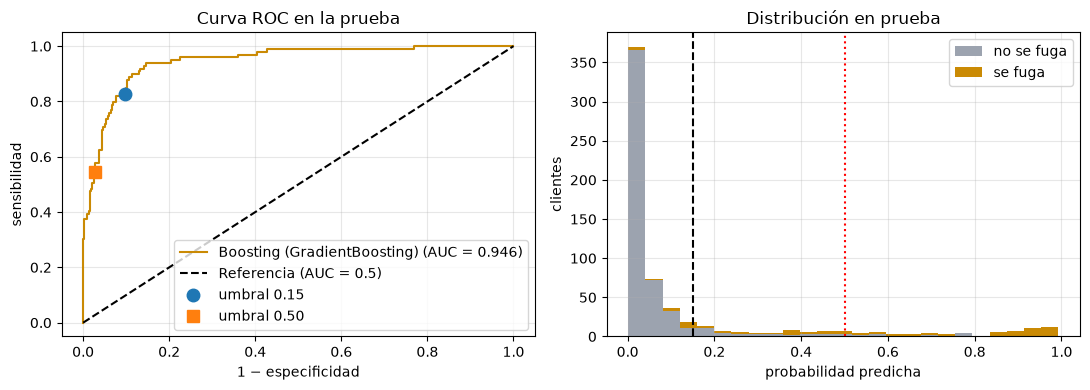

In [14]:
final = clone(MODELOS[ELEGIDO]).fit(tr[PRED], ytr)
p_te = final.predict_proba(te[PRED])[:, 1]
ref = clone(MODELOS["Referencia (tasa positiva)"]).fit(tr[PRED], ytr)
p_ref = ref.predict_proba(te[PRED])[:, 1]
print("Tasa positiva del entrenamiento completo (referencia):", round(ytr.mean(), 4), "| tasa de fuga en la prueba:", round(yte.mean(), 4))

met = pd.DataFrame({
    ELEGIDO: {"log loss": log_loss(yte, p_te), "Brier": brier_score_loss(yte, p_te), "AUC": roc_auc_score(yte, p_te)},
    "Referencia": {"log loss": log_loss(yte, p_ref), "Brier": brier_score_loss(yte, p_ref), "AUC": roc_auc_score(yte, p_ref)},
}).T
print(met.to_string())

filas = {}
for nombre, pr in [(ELEGIDO, p_te), ("Referencia", p_ref)]:
    for t in (T_STAR, 0.50):
        tn, fp, fn, tp = matriz(yte, pr >= t)
        filas[(nombre, f"t={t:.2f}")] = {"VN": tn, "FP": fp, "FN": fn, "VP": tp, "sensibilidad": tp / (tp + fn),
                                          "especificidad": tn / (tn + fp), "C = FP+5FN": fp + 5 * fn, "C/n": (fp + 5 * fn) / len(yte)}
print()
tab_cm = pd.DataFrame(filas).T
for c_ in ["VN", "FP", "FN", "VP", "C = FP+5FN"]:
    tab_cm[c_] = tab_cm[c_].astype(int)
print(tab_cm.to_string())

fpr, tpr, _ = roc_curve(yte, p_te)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr, color="#CA8A04", label=f"{ELEGIDO} (AUC = {roc_auc_score(yte, p_te):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="Referencia (AUC = 0.5)")
for t, mk in [(T_STAR, "o"), (0.50, "s")]:
    tn, fp, fn, tp = matriz(yte, p_te >= t)
    ax[0].plot(fp / (fp + tn), tp / (tp + fn), mk, ms=9, label=f"umbral {t:.2f}")
ax[0].set(xlabel="1 − especificidad", ylabel="sensibilidad", title="Curva ROC en la prueba"); ax[0].legend()
ax[1].hist([p_te[yte == 0], p_te[yte == 1]], bins=25, stacked=True, label=["no se fuga", "se fuga"], color=["#9CA3AF", "#CA8A04"])
ax[1].axvline(T_STAR, color="k", ls="--"); ax[1].axvline(0.5, color="r", ls=":")
ax[1].set(xlabel="probabilidad predicha", ylabel="clientes", title="Distribución en prueba"); ax[1].legend()
plt.tight_layout(); plt.show()

> **En el Taller 3 esto corresponde a…** Reajusta **el mismo `Pipeline` elegido** con todo `clientes_entrenamiento.csv` (nunca con la prueba) y evalúa en `clientes_prueba.csv` **una sola vez**. Informa log loss, Brier, AUC, **la curva ROC** (figura) y, para `t*` (el de 3(a)) y para 0.50: matriz de confusión, sensibilidad, especificidad y `C/n` con `C = FP + 5·FN`. Incluye el **modelo de referencia** con la tasa del entrenamiento completo. Luego responde las tres preguntas finales con argumentos: *qué recomendarían al banco* (a quién llamar y con qué umbral, en términos del costo), *qué permiten concluir los resultados* (calidad de ordenamiento, calibración, costo frente a la referencia y a 0.50) y *qué falta verificar para una campaña futura* (estabilidad temporal, que `contactos_campana` y otras variables estén disponibles **antes** de la llamada, costos reales FP/FN, incertidumbre por tamaño de muestra, equidad entre grupos, monitoreo). El enunciado pide expresamente extenderse en esto.

**Interpretación.**

| Prueba (630 clientes) | log loss | Brier | AUC |
|---|---|---|---|
| Boosting | 0.2073 | 0.0637 | 0.9456 |
| Referencia (tasa 0.157) | 0.4349 | 0.1324 | 0.5000 |

| Regla | VN | FP | FN | VP | Sensibilidad | Especificidad | C | C/n |
|---|---|---|---|---|---|---|---|---|
| Boosting, t\* = 0.15 | 479 | 52 | 17 | 82 | 0.828 | 0.902 | 137 | 0.218 |
| Boosting, t = 0.50 | 516 | 15 | 45 | 54 | 0.545 | 0.972 | 240 | 0.381 |
| Referencia, t = 0.15 (alerta a todos) | 0 | 531 | 0 | 99 | 1.000 | 0.000 | 531 | 0.843 |
| Referencia, t = 0.50 (no alerta a nadie) | 531 | 0 | 99 | 0 | 0.000 | 1.000 | 495 | 0.786 |

- **Qué se concluye.** El modelo conserva su calidad en datos no vistos: AUC 0.946 (0.962 en OOF) y log loss 0.207 (0.179 en OOF), una degradación pequeña y esperable (con solo 99 fugas en la prueba el error de estimación es apreciable). Supera a la referencia por mucho (log loss 0.207 vs 0.435).
- **Qué recomendar.** Usar el boosting con **t\* = 0.15**: reduce el costo medio a 0.218 por cliente, **43 % menos** que con 0.50 (0.381) y **72 % menos** que la mejor regla trivial (0.786, «no alertar a nadie»). A cambio, hay 52 contactos de retención a clientes que no se iban (10 % de quienes se quedan) y se pierden 17 de las 99 fugas. Hay que comunicar esa tasa de falsas alarmas y verificar que el costo unitario de contactar sea efectivamente 1/5 del de perder un cliente.
- **Qué falta verificar** antes de una campaña futura: (i) la incertidumbre de las métricas (intervalos por *bootstrap*; la prueba es una sola muestra pequeña); (ii) los costos reales de FP y FN; (iii) la calibración en la prueba y la estabilidad en el tiempo (deriva de datos); (iv) que **todas las variables estén disponibles antes de decidir** (`clv` se excluyó por el supuesto; `n_contactos` y similares deben medirse hasta el momento de la decisión); (v) que contactar a un cliente de riesgo **efectivamente reduzca** la fuga (predecir no es causar; haría falta un experimento A/B); (vi) la equidad entre grupos de clientes y el monitoreo continuo.

---
## Parte 4 · Componentes principales y agrupamiento (8 pts)

### Variables y estandarización
El enunciado fija **cuatro variables** del entrenamiento, **estandarizadas con media y desviación muestral** (divisor n − 1). Aquí elegimos cuatro numéricas de la base de churn que mantienen la mezcla del taller (conteos asimétricos y una medida continua): `numero_fallas`, `frec_llamadas`, `frec_sms` y `n_contactos`. Cuidado: `StandardScaler` usa divisor n (no n − 1); para seguir la instrucción se estandariza a mano con `std(ddof=1)`.

In [15]:
V4 = ["numero_fallas", "frec_llamadas", "frec_sms", "n_contactos"]
X4_raw = tr[V4].copy()
print("Faltantes en las 4 variables (entrenamiento):", X4_raw.isna().sum().to_dict())
med = X4_raw.median()
X4 = X4_raw.fillna(med)                          # imputación con la mediana del entrenamiento (afecta a muy pocas filas)
mu, sd = X4.mean(), X4.std(ddof=1)              # media y desviación MUESTRAL
Z = (X4 - mu) / sd
print("\nMedias de Z:", Z.mean().round(10).to_dict())
print("Desv. muestrales de Z:", Z.std(ddof=1).round(10).to_dict())
print("\nDescriptivos originales:")
print(X4.describe().T[["mean", "std", "min", "50%", "max"]].to_string())
print("\nCorrelaciones:")
print(X4.corr().round(3).to_string())

Faltantes en las 4 variables (entrenamiento): {'numero_fallas': 0, 'frec_llamadas': 26, 'frec_sms': 4, 'n_contactos': 2}

Medias de Z: {'numero_fallas': -0.0, 'frec_llamadas': -0.0, 'frec_sms': -0.0, 'n_contactos': 0.0}
Desv. muestrales de Z: {'numero_fallas': 1.0, 'frec_llamadas': 1.0, 'frec_sms': 1.0, 'n_contactos': 1.0}

Descriptivos originales:
                 mean      std    min     50%      max
numero_fallas  7.6841   7.3171 0.0000  6.0000  36.0000
frec_llamadas 71.4321  58.1253 0.0000 55.0000 255.0000
frec_sms      73.1921 111.9268 0.0000 20.5000 522.0000
n_contactos   23.5909  17.1092 0.0000 21.0000  97.0000

Correlaciones:
               numero_fallas  frec_llamadas  frec_sms  n_contactos
numero_fallas         1.0000         0.5720   -0.0190       0.5190
frec_llamadas         0.5720         1.0000    0.1020       0.7620
frec_sms             -0.0190         0.1020    1.0000       0.0990
n_contactos           0.5190         0.7620    0.0990       1.0000


> **En el Taller 3 esto corresponde a…** Variables del enunciado: **`edad`, `saldo`, `contactos_campana`, `contactos_previos`**, tomadas del **conjunto de entrenamiento**, estandarizadas con `media` y `std(ddof=1)` (la desviación **muestral**). Con `bank` no hay faltantes que imputar; no incluyas `log_contactos_previos` ni `dias_previos`: son cuatro variables exactamente las nombradas. Estandariza una vez y reutiliza la misma matriz `Z` en PCA, K-means y (la distancia de Mahalanobis no la necesita, pero da lo mismo con `Z` o con los datos originales). Las puntuaciones de la prueba **no** se usan en las partes 4 y 5.

### 4(a) PCA: varianza explicada, cargas y plano (3 pts)

Varianza explicada:
      autovalor  % varianza  % acumulado
PC1     2.2515      0.5629       0.5629
PC2     1.0073      0.2518       0.8147
PC3     0.5070      0.1267       0.9415
PC4     0.2342      0.0585       1.0000

PC1 + PC2 = 0.8147

Cargas (autovectores; filas = variables):
                 PC1     PC2     PC3     PC4
numero_fallas 0.5220 -0.2030  0.8220 -0.1020
frec_llamadas 0.6070  0.0110 -0.2910  0.7400
frec_sms      0.0880  0.9790  0.1830 -0.0150
n_contactos   0.5930  0.0220 -0.4540 -0.6650

Cargas escaladas (autovector·√autovalor = correlación variable–PC):
                 PC1     PC2     PC3     PC4
numero_fallas 0.7830 -0.2030  0.5850 -0.0490
frec_llamadas 0.9100  0.0110 -0.2070  0.3580
frec_sms      0.1320  0.9830  0.1310 -0.0070
n_contactos   0.8900  0.0220 -0.3230 -0.3220


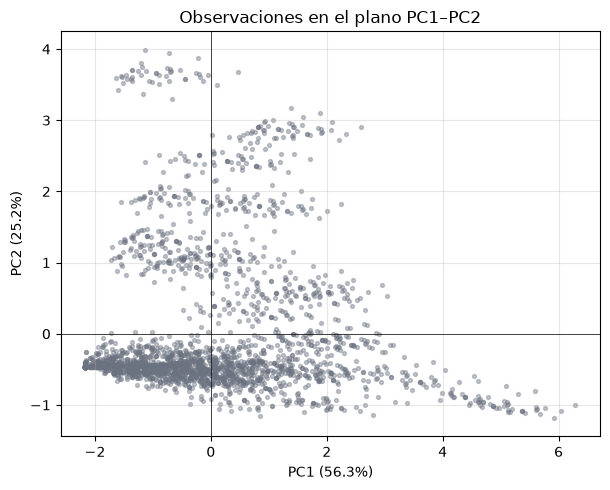

In [16]:
pca = PCA(n_components=4).fit(Z)
var = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i}" for i in range(1, 5)])
print("Varianza explicada:\n", pd.DataFrame({"autovalor": pca.explained_variance_, "% varianza": var, "% acumulado": var.cumsum()}).to_string())
print("\nPC1 + PC2 =", round(var["PC1"] + var["PC2"], 4))
cargas = pd.DataFrame(pca.components_.T, index=V4, columns=var.index)
print("\nCargas (autovectores; filas = variables):")
print(cargas.round(3).to_string())
print("\nCargas escaladas (autovector·√autovalor = correlación variable–PC):")
print((cargas * np.sqrt(pca.explained_variance_)).round(3).to_string())

scores = pd.DataFrame(pca.transform(Z), columns=var.index, index=tr.index)
fig, ax = plt.subplots(figsize=(6.2, 5))
ax.scatter(scores["PC1"], scores["PC2"], s=8, alpha=0.4, color="#6B7280")
ax.set(xlabel=f"PC1 ({var['PC1']:.1%})", ylabel=f"PC2 ({var['PC2']:.1%})", title="Observaciones en el plano PC1–PC2")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
plt.tight_layout(); plt.show()

> **En el Taller 3 esto corresponde a…** Mismo código con `Z` de `edad, saldo, contactos_campana, contactos_previos`. Informa **varianza explicada por PC1 y PC2, su suma, las cargas** (tabla variables × componentes), y el **gráfico PC1–PC2**. Para la pregunta «¿qué información resume la proyección y cuál omite?» razona con tus números: porcentaje de varianza retenida y omitida (PC3–PC4), qué variables dominan cada componente (signos y magnitudes de las cargas), que PCA **no usa `contrata`** y que dos observaciones cercanas en el plano pueden diferir en las dimensiones omitidas. Los **signos** de los componentes son arbitrarios (cambian entre Python y R): interpreta magnitudes y relaciones, no el signo absoluto.

**Interpretación.**

- **Varianza explicada**: PC1 = 56.3 %, PC2 = 25.2 %, **suma = 81.5 %**; PC3 = 12.7 % y PC4 = 5.9 % quedan fuera del plano (18.5 %).
- **Cargas**: PC1 tiene signos positivos en `numero_fallas` (0.52), `frec_llamadas` (0.61) y `n_contactos` (0.59) y casi cero en `frec_sms` (0.09): es un componente de **«nivel general de actividad»** (clientes con muchas fallas, llamadas y contactos frente a los de poca actividad). PC2 es prácticamente `frec_sms` (0.98): el eje del **uso de SMS**, que casi no se relaciona con las otras tres (correlaciones de alrededor de 0.1 o menos).
- **Qué resume y qué omite el plano**: resume el nivel conjunto de actividad y el uso de SMS, 81 % de la variación de las cuatro variables estandarizadas. **Omite** el 18.5 % restante, principalmente el contraste entre `numero_fallas` y `n_contactos` (PC3: 0.82 vs −0.45), y por construcción **no usa `fuga`**: dos clientes cercanos en el plano pueden diferir en lo omitido, y la dirección de máxima varianza no es necesariamente la que mejor separa la respuesta. Los signos de los componentes son arbitrarios.

### 4(b) K-means con k = 2, 3 y 4 (5 pts)
`KMeans(n_clusters=k, n_init=30, random_state=2026)` sobre `Z`. Se compara **WSS** (suma de cuadrados intra-grupo, `inertia_`) y **silueta media**, y se elige el k de mayor silueta. Luego, tamaños, perfiles (en unidades originales), grupos en el plano PCA y tasa de fuga dentro de cada grupo.

         WSS  silueta media
2 6,436.2935         0.3712
3 4,628.1521         0.3998
4 3,716.0606         0.3335

k elegido (mayor silueta) = 3

Perfiles (medias en unidades originales), tamaño y tasa de fuga por grupo:
          n  numero_fallas  frec_llamadas  frec_sms  n_contactos  % del total  tasa de fuga
grupo                                                                                      
0       437         5.5858        68.6476  286.5812      23.4211       0.1734        0.0092
1      1382         4.6729        39.1404   16.0152      14.3640       0.5484        0.2467
2       701        14.9287       136.8302   52.8887      41.8873       0.2782        0.0728

Perfiles en unidades estandarizadas (media de Z):
       numero_fallas  frec_llamadas  frec_sms  n_contactos
grupo                                                     
0            -0.2900        -0.0500    1.9100      -0.0100
1            -0.4100        -0.5600   -0.5100      -0.5400
2             0.9900         1.130

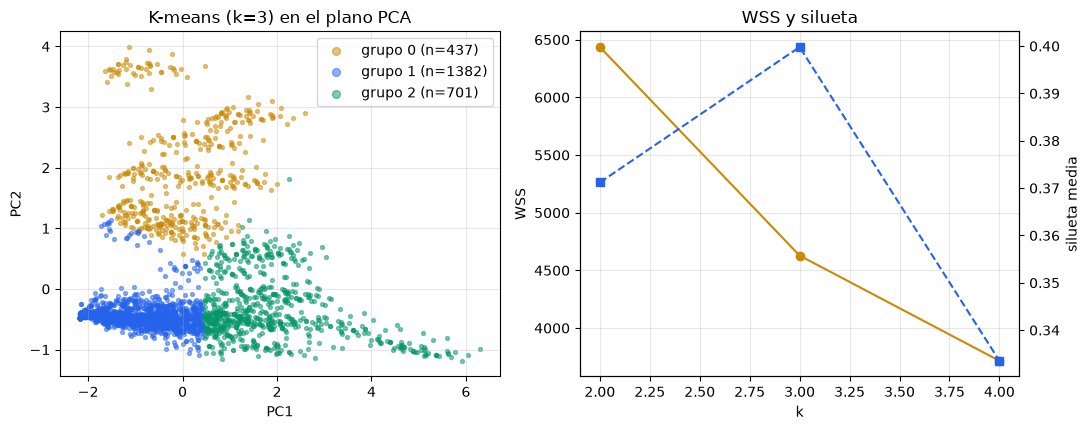

In [17]:
res_k = {}
for k in (2, 3, 4):
    km = KMeans(n_clusters=k, n_init=30, random_state=SEMILLA).fit(Z)
    res_k[k] = dict(modelo=km, WSS=km.inertia_, silueta=silhouette_score(Z, km.labels_))
print(pd.DataFrame({k: {"WSS": v["WSS"], "silueta media": v["silueta"]} for k, v in res_k.items()}).T.to_string())
K_STAR = max(res_k, key=lambda k: res_k[k]["silueta"])
print("\nk elegido (mayor silueta) =", K_STAR)

km = res_k[K_STAR]["modelo"]
lab = pd.Series(km.labels_, index=tr.index, name="grupo")
perf = X4.assign(grupo=lab).groupby("grupo").agg(["mean"]).droplevel(1, axis=1)
perf.insert(0, "n", lab.value_counts().sort_index())
perf["% del total"] = perf["n"] / len(lab)
perf["tasa de fuga"] = pd.Series(ytr, index=tr.index).groupby(lab).mean()
print("\nPerfiles (medias en unidades originales), tamaño y tasa de fuga por grupo:")
print(perf.to_string())
print("\nPerfiles en unidades estandarizadas (media de Z):")
print(Z.assign(grupo=lab).groupby("grupo").mean().round(2).to_string())
print("\nTasa de fuga global:", round(ytr.mean(), 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
colores = ["#CA8A04", "#2563EB", "#059669", "#DC2626"]
for g in sorted(lab.unique()):
    m = lab == g
    ax[0].scatter(scores.loc[m, "PC1"], scores.loc[m, "PC2"], s=8, alpha=0.5, color=colores[g], label=f"grupo {g} (n={m.sum()})")
ax[0].set(xlabel="PC1", ylabel="PC2", title=f"K-means (k={K_STAR}) en el plano PCA"); ax[0].legend(markerscale=2)
ks = list(res_k)
ax[1].plot(ks, [res_k[k]["WSS"] for k in ks], "o-", color="#CA8A04"); ax[1].set(xlabel="k", ylabel="WSS", title="WSS y silueta")
ax2 = ax[1].twinx(); ax2.plot(ks, [res_k[k]["silueta"] for k in ks], "s--", color="#2563EB"); ax2.set_ylabel("silueta media"); ax2.grid(False)
plt.tight_layout(); plt.show()

> **En el Taller 3 esto corresponde a…** `KMeans(n_clusters=k, n_init=30, random_state=2026)` para k = 2, 3 y 4 **sobre las cuatro variables estandarizadas** (nunca sobre las originales ni sobre los dos componentes). En R: `kmeans(Z, centers = k, nstart = 30)` con `set.seed(2026)`. Tabla con `tot.withinss` (WSS) y silueta media por k (`cluster::silhouette`); **elige el k de mayor silueta** (no el del «codo»). Informa tamaños, perfiles (medias por grupo en unidades originales: describe con palabras, p. ej. «clientes con saldo alto y pocos contactos»), el gráfico en el plano PCA coloreado por grupo y la **proporción de `contrata` dentro de cada grupo**. Explicación pedida: los grupos se forman **sin mirar `contrata`** con solo 4 variables y dependen de k y de la escala; una alta proporción de contrata en un grupo no convierte al grupo en una clase «predicha»: no hay umbral, no hay modelo evaluado, y los grupos no se construyeron para separar la respuesta.

**Interpretación.**

| k | WSS | silueta media |
|---|---|---|
| 2 | 6 436 | 0.371 |
| 3 | 4 628 | **0.400** |
| 4 | 3 716 | 0.334 |

- **Elección**: el WSS **siempre baja** al aumentar k (no sirve solo para elegir); la silueta es máxima en **k = 3** (0.400), que es la regla del enunciado.
- **Grupos (k = 3)**: **grupo 0** (437; 17.3 %): usuarios intensivos de SMS (`frec_sms` ≈ 287, z = +1.9) con actividad promedio en lo demás; fuga **0.9 %**. **Grupo 1** (1 382; 54.8 %): baja actividad en todo (z entre −0.4 y −0.6: ≈ 39 llamadas, 16 SMS, 14 contactos); fuga **24.7 %**. **Grupo 2** (701; 27.8 %): mucha actividad en fallas, llamadas y contactos (z ≈ +1.0 a +1.1); fuga **7.3 %**. Tasa global: 15.7 %.
- **Por qué los grupos no son clases predichas**: se formaron **sin mirar `fuga`** y con solo cuatro variables; no hay umbral ni modelo evaluado. En el grupo 1, el de mayor fuga, el **75 % de los clientes no se fuga**: rotularlo «se fuga» daría un 75 % de falsas alarmas (aunque contiene unas 341 de las 396 fugas, 86 %, en el 55 % de los clientes). Sirve para **describir perfiles**, no para decidir: los grupos dependen de k y de la escala, y la tasa de fuga por grupo es un resultado descriptivo, no una predicción.

---
## Parte 5 · Detección de anomalías (6 pts)

### 5(a) Distancia de Mahalanobis al cuadrado y corte χ² (3 pts)
Con media muestral $m$ y covarianza muestral $S$ de las cuatro variables:
$$D^2_i = (x_i - m)^\top S^{-1} (x_i - m).$$
Si los datos fueran normales multivariados, $D^2 \sim \chi^2_4$ y el corte natural sería su cuantil 0.99.

In [18]:
S = np.cov(X4.to_numpy(), rowvar=False)                   # covarianza muestral (divisor n - 1)
dif = X4.to_numpy() - X4.mean().to_numpy()
d2 = np.einsum("ij,jk,ik->i", dif, np.linalg.inv(S), dif)
CORTE = chi2.ppf(0.99, df=4)
marc = d2 > CORTE
print("Corte (chi-cuadrado 0.99, 4 g.l.):", round(CORTE, 4))
print("Registros marcados:", int(marc.sum()), "de", len(d2), "->", f"{marc.mean():.2%}", "(esperado si fuera normal: 1.00%)")
print("Mediana de D^2:", round(np.median(d2), 3), "| mediana teórica chi2(4):", round(chi2.ppf(0.5, 4), 3))
print("Control: Mahalanobis^2 con datos estandarizados es idéntico:", np.allclose(d2, np.einsum("ij,jk,ik->i", Z.to_numpy(), np.linalg.inv(np.cov(Z.to_numpy(), rowvar=False)), Z.to_numpy())))

top = pd.Series(d2, index=tr.index).nlargest(2)
dd = tr.loc[top.index, ["id_cliente"] + V4 + ["fuga"]].copy()
dd.insert(1, "D2", top.values)
print("\nLos dos registros con mayor D^2 (valores originales):")
print(dd.to_string())
print("\nSus puntajes z (cuántas desv. muestrales de la media):")
print(Z.loc[top.index].round(2).to_string())
print("\nPercentiles de cada variable (0-100) de esos registros:")
print(X4.rank(pct=True).loc[top.index].mul(100).round(1).to_string())
print("\nResumen de las variables (media y desv. muestral):")
print(pd.DataFrame({"media": X4.mean(), "sd": X4.std(ddof=1), "máx": X4.max()}).T.round(2).to_string())

Corte (chi-cuadrado 0.99, 4 g.l.): 13.2767
Registros marcados: 153 de 2520 -> 6.07% (esperado si fuera normal: 1.00%)
Mediana de D^2: 2.32 | mediana teórica chi2(4): 3.357
Control: Mahalanobis^2 con datos estandarizados es idéntico: True

Los dos registros con mayor D^2 (valores originales):
     id_cliente      D2  numero_fallas  frec_llamadas  frec_sms  n_contactos  fuga
384         490 34.5014              8        49.0000   51.0000      83.0000     0
991        1240 27.7323              0        35.0000   33.0000      70.0000     0

Sus puntajes z (cuántas desv. muestrales de la media):
     numero_fallas  frec_llamadas  frec_sms  n_contactos
384         0.0400        -0.3900   -0.2000       3.4700
991        -1.0500        -0.6300   -0.3600       2.7100

Percentiles de cada variable (0-100) de esos registros:
     numero_fallas  frec_llamadas  frec_sms  n_contactos
384        59.5000        44.3000   69.2000      99.5000
991        11.2000        30.6000   61.1000      97.4000

Re

> **En el Taller 3 esto corresponde a…** Idéntico con `edad, saldo, contactos_campana, contactos_previos` del entrenamiento: `D²` con la media y la covarianza **muestrales** (R: `mahalanobis(x, colMeans(x), cov(x))`, ya devuelve D² al cuadrado), corte `qchisq(0.99, df = 4)` / `chi2.ppf(0.99, 4)`, regla `D² > corte`. Informa **el corte, la cantidad y el porcentaje de marcados**, y los **dos registros de mayor D²** con sus **valores originales** (no estandarizados), incluyendo `id_cliente`. En la tabla de esos dos registros añade sus puntajes z para poder explicar qué variable (o qué combinación) los hace inusuales.

**Interpretación.**

- **Corte**: χ²(4; 0.99) = **13.277**. **153 de 2 520** registros (**6.07 %**) lo superan.
- **Dos mayores distancias**: `id_cliente` 490 con D² = 34.50 (`numero_fallas` 8, `frec_llamadas` 49, `frec_sms` 51, `n_contactos` 83) y `id_cliente` 1240 con D² = 27.73 (`numero_fallas` 0, `frec_llamadas` 35, `frec_sms` 33, `n_contactos` 70). Se informan con valores **originales**, junto con sus puntajes z para poder explicarlos.
- Comprobación: usar los datos estandarizados da exactamente los mismos D² (Mahalanobis es invariante a cambios de escala lineales).

### 5(b) ¿Por qué son inusuales? ¿Son errores? ¿Garantiza el corte un 1 %? (3 pts)

In [19]:
# Evidencia para 5(b): ¿hay variables muy asimétricas? ¿qué pasa al marcar con otro criterio? ¿cambia con una covarianza robusta?
print("Asimetría de cada variable:", X4.skew().round(2).to_dict())
print("Mayor |z| univariado de cada uno de los 2 registros:", Z.loc[top.index].abs().max(axis=1).round(2).to_dict())
for q in (0.95, 0.99, 0.999):
    c = chi2.ppf(q, 4)
    print(f"  cuantil {q}: corte {c:.2f} -> marcados {int((d2 > c).sum())} ({(d2 > c).mean():.2%}) | esperado {1 - q:.2%}")

# Mahalanobis sin los 2 registros más extremos (¿cuánto influyen en S?)
resto = X4.drop(index=top.index)
S2 = np.cov(resto.to_numpy(), rowvar=False)
d2b = np.einsum("ij,jk,ik->i", X4.to_numpy() - resto.mean().to_numpy(), np.linalg.inv(S2), X4.to_numpy() - resto.mean().to_numpy())
print("\nD^2 de los dos registros recalculando m y S SIN ellos:", np.round(d2b[[X4.index.get_loc(i) for i in top.index]], 1),
      "| antes:", np.round(top.values, 1))
print("Registros marcados con m y S sin ellos:", int((d2b > CORTE).sum()))

Asimetría de cada variable: {'numero_fallas': 1.1, 'frec_llamadas': 1.13, 'frec_sms': 1.93, 'n_contactos': 1.02}
Mayor |z| univariado de cada uno de los 2 registros: {384: 3.47, 991: 2.71}
  cuantil 0.95: corte 9.49 -> marcados 274 (10.87%) | esperado 5.00%
  cuantil 0.99: corte 13.28 -> marcados 153 (6.07%) | esperado 1.00%
  cuantil 0.999: corte 18.47 -> marcados 49 (1.94%) | esperado 0.10%

D^2 de los dos registros recalculando m y S SIN ellos: [35.4 28.4] | antes: [34.5 27.7]
Registros marcados con m y S sin ellos: 155


> **En el Taller 3 esto corresponde a…** Responde en tres partes, siempre con **tus números**: (i) *por qué son inusuales*: qué variable(s) toman valores extremos o qué combinación contradice la correlación entre las variables (D² mide distancia **en la métrica de la covarianza**: un valor moderado en una variable puede ser raro dado el valor de otra); (ii) *¿demuestra errores?* No: una distancia grande es una **señal de revisión**, no una prueba; en `bank`, un `saldo` muy alto o muchos `contactos_campana` pueden ser clientes reales y valiosos (o una captura errónea: hay que verificarlo); (iii) *¿el corte garantiza marcar al 1 %?* No: 1 % es lo esperado **solo si** los datos son normales multivariados y m y S se conocen; con datos asimétricos y de cola pesada (como `saldo`) se marcan bastantes más, y m y S estimados con los mismos datos (inflados por los extremos) cambian el resultado. Antes de eliminar un registro: verificar unidades y captura, buscar duplicados, revisar el resto de sus columnas y el contexto de negocio, comparar el modelo con y sin el registro, decidir con un criterio escrito (conservar, corregir o eliminar) y no eliminar si el caso es una población real de interés.

**Interpretación.**

- **¿Por qué son inusuales?** En ambos, `n_contactos` es muy alto (83 y 70; z = 3.47 y 2.71; percentiles 99.5 y 97.4), pero `frec_llamadas` es **menor que el promedio** (49 y 35 vs 71; z = −0.39 y −0.63), aunque ambas variables están correlacionadas (r = 0.76): lo esperable es que muchos contactos vengan con muchas llamadas. Su rareza es una **combinación que contradice la correlación**, más que un valor extremo en una sola variable: ningún z univariado pasa de 3.5. Eso es lo que mide Mahalanobis y lo que no ve una regla variable por variable.
- **¿Demuestra errores?** No. Un D² alto señala un registro **estadísticamente inusual**, no incorrecto: puede ser un cliente real contactado por otros canales, o un error de captura; la distancia no distingue entre ambos.
- **¿Garantiza marcar el 1 %?** No: marca el **6.07 %**. El 1 % solo se cumple si los datos son normales multivariados y los parámetros se conocen; aquí las variables son **asimétricas** (asimetrías 1.0 a 1.9) y de cola pesada, y la media y la covarianza se estiman con los mismos datos. Con cuantiles más exigentes también se pasa de lo esperado: 0.95 → 10.9 % (esperado 5 %); 0.999 → 1.9 % (esperado 0.1 %). Los dos registros extremos no distorsionan la covarianza (sin ellos, D² = 35.4 y 28.4; marcados 155).
- **Antes de eliminar un registro**: verificar unidades y captura contra la fuente; revisar el resto de sus columnas y el contexto de negocio; buscar duplicados; comparar resultados con y sin el registro; y dejar por escrito la decisión (conservar, corregir o eliminar). Un registro inusual puede ser justamente el caso de interés.

---
## Resumen de decisiones de esta práctica y checklist de transferencia
| Paso | Decisión en la práctica | Qué hacer con `bank` |
|---|---|---|
| Variable prohibida | `clv` (supuesto de la práctica) | `duracion` (+ `id_cliente`, `pliegue`, `contrata`) |
| Pliegues | creados aquí con semilla 2026 | **usar la columna `pliegue` dada** |
| Indicador + log | `sin_sms`, `log_frec_sms` | `contactado_antes`, `log_contactos_previos` |
| One-hot | `tipo_plan`, `estado`, `nivel_monto` | todas las categóricas, `unknown` incluida |
| Selección | F de ANOVA k = 10 dentro del `Pipeline` | igual, informando columnas por pliegue |
| Modelos | 9 filas con la misma configuración | idéntico |
| Elegido | menor log loss OOF probabilístico | su propio ganador (puede ser otro) |
| Umbral | min FP + 5·FN con `p ≥ t` | idéntico, con **tus** OOF |
| Cuatro variables | `numero_fallas`, `frec_llamadas`, `frec_sms`, `n_contactos` | `edad`, `saldo`, `contactos_campana`, `contactos_previos` |
| Mahalanobis | corte χ² 0.99, 4 g.l. | idéntico |

### Lista de verificación antes de entregar (la guía en PDF la amplía)
- [ ] Un solo lenguaje (R **o** Python) en todo el taller.
- [ ] `duracion`, `id_cliente`, `pliegue` y `contrata` fuera de los predictores.
- [ ] Imputación, escala, one-hot y selección **dentro** de cada pliegue (`Pipeline`).
- [ ] Se usó la columna `pliegue` entregada; semilla 2026; clase positiva = 1.
- [ ] SVM: puntaje de decisión y solo AUC. Árboles: log loss medio de entrenamiento de los cinco ajustes.
- [ ] Modelo elegido = menor log loss OOF probabilístico; regla escrita.
- [ ] Prueba usada una sola vez, en 3(b); referencia con la tasa del entrenamiento completo.
- [ ] PCA/K-means/Mahalanobis con las **cuatro** variables estandarizadas (media y desv. muestral).
- [ ] Notebook ejecutado de punta a punta, rutas relativas, versiones de paquetes, integrantes identificados.

## Nota para grupos que elijan **R**: correspondencia con esta práctica
| Paso | Python (esta práctica) | R (equivalente) | Ojo con… |
|---|---|---|---|
| Lectura | `pd.read_csv` | `read.csv()` / `readr::read_csv()` | rutas relativas; `stringsAsFactors` |
| Semilla | `random_state=2026` | `set.seed(2026)` antes de cada paso aleatorio | R no tiene un `random_state` por modelo |
| Pipeline por pliegue | `Pipeline` + `ColumnTransformer` | `tidymodels` (`recipes` + `workflows`) o un bucle sobre `pliegue` con `prep()`/`bake()` | la receta se ajusta solo con las filas de ajuste |
| One-hot | `OneHotEncoder` | `step_dummy()` / `model.matrix()` | niveles ausentes en el pliegue de validación |
| Logística sin penalización | `LogisticRegression(penalty=None)` | `glm(y ~ ., family = binomial)` | separación perfecta: avisos de convergencia |
| Selección F de ANOVA | `SelectKBest(f_classif, k=10)` | `anova`/`oneway.test` por columna o `caret::sbf` | calcular en las filas de ajuste |
| Árbol | `DecisionTreeClassifier(max_depth, min_samples_leaf=20)` | `rpart(..., control = rpart.control(maxdepth, minbucket = 20, cp = 0))` | `cp = 0` evita la poda; `minbucket` ≈ mínimo por hoja |
| Random Forest | `n_estimators=200, max_features="sqrt", min_samples_leaf=10` | `ranger(num.trees = 200, mtry = floor(sqrt(p)), min.node.size = 10, probability = TRUE)` | `min.node.size` no es idéntico a `min_samples_leaf` |
| Boosting | `GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=…)` | `xgboost` / `gbm` (`n.trees`, `interaction.depth`, `shrinkage`) | informar variante y tasa |
| SVM radial | `SVC(C=1, gamma=1/p)` + `decision_function` | `e1071::svm(kernel = "radial", cost = 1, gamma = 1/p, decision.values = TRUE)` | el signo del puntaje depende del orden de las clases |
| Naive Bayes | `GaussianNB` | `e1071::naiveBayes()` (gaussiano para numéricas) | una dummy 0/1 no es gaussiana |
| Métricas | `log_loss`, `brier_score_loss`, `roc_auc_score` | `MLmetrics::LogLoss`, `mean((p - y)^2)`, `pROC::auc` | clase positiva = 1 |
| PCA | `PCA` sobre `Z` | `prcomp(Z)` (con `Z` ya estandarizada con `sd()`, que es muestral) | signos distintos |
| K-means | `KMeans(n_init=30)` | `kmeans(Z, centers = k, nstart = 30)` | algoritmo y semilla distintos: etiquetas permutadas |
| Silueta | `silhouette_score` | `cluster::silhouette(km$cluster, dist(Z))` | usar la media de `sil_width` |
| Mahalanobis | `einsum` con `inv(S)` | `mahalanobis(x, colMeans(x), cov(x))` | R ya devuelve D² |
| Corte | `chi2.ppf(0.99, 4)` | `qchisq(0.99, df = 4)` | — |

El profesor aceptó expresamente **diferencias numéricas** entre lenguajes (algoritmos, semillas, signos de componentes) siempre que la implementación y la regla de selección estén justificadas.